In [1]:

import pandas as pd
import numpy as np
import glob
import os

files = glob.glob("/content/**/*.csv", recursive=True)

print("CSV files found:", files)


CSV files found: ['/content/sample_data/mnist_train_small.csv', '/content/sample_data/california_housing_train.csv', '/content/sample_data/california_housing_test.csv', '/content/sample_data/mnist_test.csv']


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (1).zip to archive (1).zip


In [4]:

import os

print(os.listdir("/content"))


['.config', 'archive (1).zip', 'sample_data']


In [5]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())
print(df.columns.tolist())


Saving archive (1).zip to archive (1) (1).zip
Dataset loaded successfully!
Shape: (22012, 129)
         country  year iso_code  population  gdp  biofuel_cons_change_pct  \
0  ASEAN (Ember)  2000      NaN         NaN  NaN                      NaN   
1  ASEAN (Ember)  2001      NaN         NaN  NaN                      NaN   
2  ASEAN (Ember)  2002      NaN         NaN  NaN                      NaN   
3  ASEAN (Ember)  2003      NaN         NaN  NaN                      NaN   
4  ASEAN (Ember)  2004      NaN         NaN  NaN                      NaN   

   biofuel_cons_change_twh  biofuel_cons_per_capita  biofuel_consumption  \
0                      NaN                      NaN                  NaN   
1                      NaN                      NaN                  NaN   
2                      NaN                      NaN                  NaN   
3                      NaN                      NaN                  NaN   
4                      NaN                      NaN           

In [7]:

print("Column names in your dataset:")
print(df.columns.tolist())

print("\nFirst five rows:")
print(df.head())


Column names in your dataset:
['country', 'year', 'iso_code', 'population', 'gdp', 'biofuel_cons_change_pct', 'biofuel_cons_change_twh', 'biofuel_cons_per_capita', 'biofuel_consumption', 'biofuel_elec_per_capita', 'biofuel_electricity', 'biofuel_share_elec', 'biofuel_share_energy', 'carbon_intensity_elec', 'coal_cons_change_pct', 'coal_cons_change_twh', 'coal_cons_per_capita', 'coal_consumption', 'coal_elec_per_capita', 'coal_electricity', 'coal_prod_change_pct', 'coal_prod_change_twh', 'coal_prod_per_capita', 'coal_production', 'coal_share_elec', 'coal_share_energy', 'electricity_demand', 'electricity_generation', 'electricity_share_energy', 'energy_cons_change_pct', 'energy_cons_change_twh', 'energy_per_capita', 'energy_per_gdp', 'fossil_cons_change_pct', 'fossil_cons_change_twh', 'fossil_elec_per_capita', 'fossil_electricity', 'fossil_energy_per_capita', 'fossil_fuel_consumption', 'fossil_share_elec', 'fossil_share_energy', 'gas_cons_change_pct', 'gas_cons_change_twh', 'gas_consumpt

In [11]:

# Select India
india = df[df["country"] == "India"].copy()

# Select year and energy consumption
india = india[["year", "primary_energy_consumption"]].copy()

# Convert to numeric values
india["year"] = pd.to_numeric(india["year"], errors="coerce")
india["primary_energy_consumption"] = pd.to_numeric(
    india["primary_energy_consumption"], errors="coerce"
)

# Sort chronologically
india = india.sort_values("year").reset_index(drop=True)

# Handle missing energy values
india["primary_energy_consumption"] = (
    india["primary_energy_consumption"]
    .interpolate(method="linear")
    .ffill()
    .bfill()
)

india = india.dropna().drop_duplicates(subset=["year"])
india = india.sort_values("year").reset_index(drop=True)

print("Country: India")
print("Number of yearly records:", len(india))
print("\nFirst five records:")
print(india.head())
print("\nLast five records:")
print(india.tail())


Country: India
Number of yearly records: 123

First five records:
   year  primary_energy_consumption
0  1900                     619.451
1  1901                     619.451
2  1902                     619.451
3  1903                     619.451
4  1904                     619.451

Last five records:
     year  primary_energy_consumption
118  2018                    9081.509
119  2019                    9310.841
120  2020                    8821.111
121  2021                    9584.976
122  2022                   10123.443


In [12]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

values = india["primary_energy_consumption"].values.reshape(-1, 1)
years = india["year"].values

# Split chronologically: 80% training, 20% testing
split_index = int(len(values) * 0.8)

# Normalize using training data only
scaler = MinMaxScaler()
scaler.fit(values[:split_index])
scaled = scaler.transform(values)

# Use five previous years to predict the next year
X, y, target_indices = [], [], []

for i in range(5, len(scaled)):
    X.append(scaled[i-5:i])
    y.append(scaled[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Normalization completed!")
print("Total sequences:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input shape:", X.shape)
print("Years per sequence:", X.shape[1])


Normalization completed!
Total sequences: 118
Training samples: 93
Testing samples: 25
Input shape: (118, 5, 1)
Years per sequence: 5


In [13]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

tf.random.set_seed(42)
np.random.seed(42)

model = Sequential([
    Input(shape=(5, 1)),
    LSTM(32),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    shuffle=False,
    verbose=1
)

print("LSTM model training completed!")


Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0287    
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0153     
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0103 
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0075 
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0040 
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0014 
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.9204e-04 
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.2397e-04 
Epoch 9/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.8913e-04 
Epoch 10/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.8577e-04 
Epoch 11/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.8655e-04 
Epoch 12/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.7384e-04 
Epoch 13/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.5913e-04 
Epoch 14/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4997e-04 
Epoch 15/50
12/12 ━━━━━━━━━━━━━━

In [15]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict energy consumption
pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values to original units
actual = scaler.inverse_transform(y_test).ravel()
predicted = scaler.inverse_transform(pred_scaled).ravel()

# Evaluate the model
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))


Mean Absolute Error (MAE): 717.0189
Root Mean Squared Error (RMSE): 943.6839


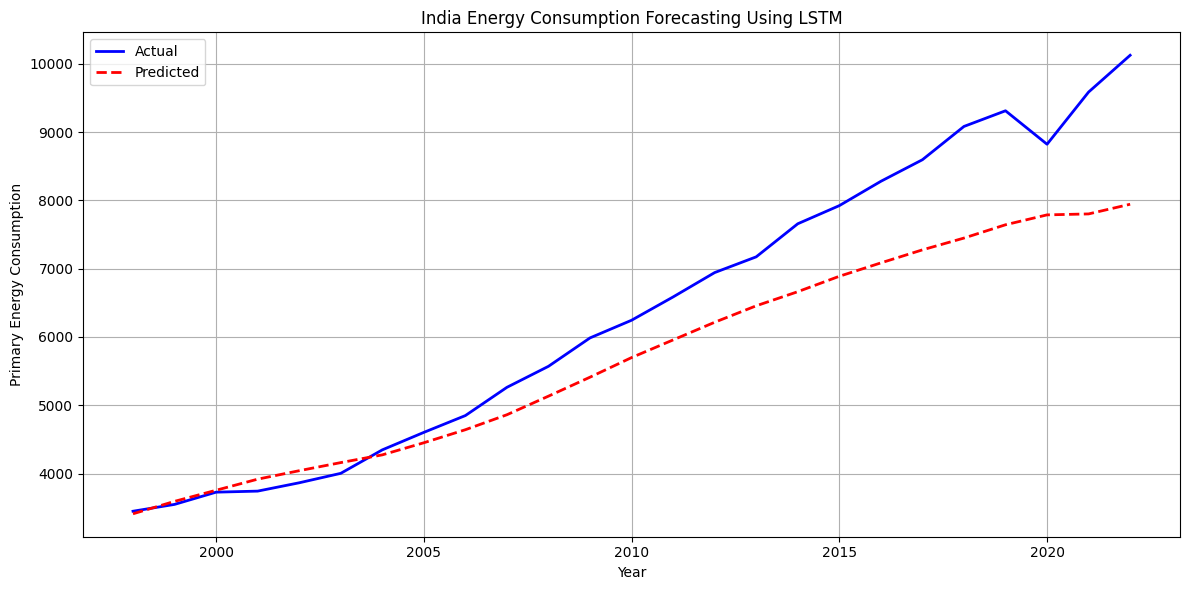

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(test_years, actual, "b-", label="Actual", linewidth=2)
plt.plot(test_years, predicted, "r--", label="Predicted", linewidth=2)

plt.xlabel("Year")
plt.ylabel("Primary Energy Consumption")
plt.title("India Energy Consumption Forecasting Using LSTM")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:

test_years = years[target_indices[test_mask]]

results = pd.DataFrame({
    "Year": test_years,
    "Actual Consumption": actual,
    "Predicted Consumption": predicted
})

print(results.round(3).to_string(index=False))


 Year  Actual Consumption  Predicted Consumption
 1998            3449.497            3411.923096
 1999            3549.489            3593.982910
 2000            3728.514            3756.685059
 2001            3743.853            3918.726074
 2002            3865.751            4042.604004
 2003            4004.078            4161.272949
 2004            4347.582            4274.500000
 2005            4603.610            4451.631836
 2006            4849.720            4642.589844
 2007            5263.111            4861.854004
 2008            5570.697            5133.948242
 2009            5986.512            5411.684082
 2010            6244.970            5698.539062
 2011            6586.134            5957.080078
 2012            6942.567            6215.369141
 2013            7172.946            6456.309082
 2014            7656.914            6662.786133
 2015            7922.428            6888.417969
 2016            8278.461            7084.326172
 2017            859

In [18]:
print("Model training history available:", "history" in globals())

Model training history available: True


In [19]:
print(history.history.keys())

dict_keys(['loss'])


In [20]:
print("Initial training loss:", history.history["loss"][0])
print("Final training loss:", history.history["loss"][-1])

Initial training loss: 0.02869071066379547
Final training loss: 0.00013987408601678908


In [21]:
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))

Mean Absolute Error (MAE): 717.0189
Root Mean Squared Error (RMSE): 943.6839


In [26]:
print("COUNTRY: India")
print("MODEL: LSTM")
print("Initial Training Loss:", round(history.history["loss"][0], 6))
print("Final Training Loss:", round(history.history["loss"][-1], 6))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

COUNTRY: India
MODEL: LSTM
Initial Training Loss: 0.028691
Final Training Loss: 0.00014
MAE: 717.0189
RMSE: 943.6839
